# Projeto — Análise Exploratória de Dados de Vendas

**Período analisado:** 1º de janeiro a 31 de dezembro de 2023  
**Fonte:** `vendas_supermercado_com_cliente.csv`  

Este notebook responde às dez perguntas do projeto. Cada seção apresenta o critério adotado e uma tabela ou gráfico produzido a partir dos dados. Valores monetários são apresentados na moeda/unidade registrada no arquivo, que não especifica moeda.

> **Limitação da base:** cada linha representa um produto em uma data, sem código de transação, cliente ou loja. Assim, “ticket médio” é tratado como valor médio de venda por registro (linha), não como valor médio de uma cesta.


In [60]:
from pathlib import Path
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
from IPython.display import display
import numpy as np

ARQUIVO = Path("vendas_supermercado_com_cliente.csv")
df = pd.read_csv(ARQUIVO, encoding="utf-8-sig")
df = df.sort_values("Data").reset_index(drop=True)
df["Mes"] = df["Data"].apply(lambda data: int(data[5:7]))
meses = {1:"Jan",2:"Fev",3:"Mar",4:"Abr",5:"Mai",6:"Jun",7:"Jul",8:"Ago",9:"Set",10:"Out",11:"Nov",12:"Dez"}
df["Mes_nome"] = df["Mes"].apply(lambda mes: meses[mes])
df["Dia_semana"] = df["Data"].apply(lambda data: datetime.strptime(data, "%Y-%m-%d").weekday())
nomes_dias = {0:"Segunda",1:"Terça",2:"Quarta",3:"Quinta",4:"Sexta",5:"Sábado",6:"Domingo"}
df["Dia_semana_nome"] = df["Dia_semana"].apply(lambda dia: nomes_dias[dia])
df["Promocao"] = df["Desconto"].gt(0)
print(f"Registros: {len(df):,} | Produtos: {df['Produto'].nunique()} | Categorias: {df['Categoria'].nunique()}")
print(f"Período: {df['Data'].min()} a {df['Data'].max()} | Valores ausentes: {int(df.isna().sum().sum())}")
display(df.head())
df.head()
df.tail()

Registros: 20,075 | Produtos: 55 | Categorias: 9
Período: 2023-01-01 a 2023-12-31 | Valores ausentes: 0


,Data,Produto,Categoria,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda,Mes,Mes_nome,Dia_semana,Dia_semana_nome,Promocao
0,2023-01-01,Maçãs,Alimentos Frescos,16.46,10,0.0,164.60,49,2715.61,1,Jan,6,Domingo,False
1,2023-01-01,Vinhos,Bebidas,7.48,5,0.0,37.40,64,1838.09,1,Jan,6,Domingo,False
2,2023-01-01,Detergentes,Produtos de Limpeza,39.99,16,0.0,639.84,22,1838.93,1,Jan,6,Domingo,False
3,2023-01-01,Sabão em pó,Produtos de Limpeza,41.39,4,0.0,165.56,65,1273.12,1,Jan,6,Domingo,False
4,2023-01-01,Amaciantes,Produtos de Limpeza,26.30,15,0.0,394.50,40,3128.13,1,Jan,6,Domingo,False


,Data,Produto,Categoria,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda,Mes,Mes_nome,Dia_semana,Dia_semana_nome,Promocao
20070,2023-12-31,Queijo,Laticínios e Ovos,12.01,12,0.19,116.7372,61,4314.63,12,Dez,6,Domingo,True
20071,2023-12-31,Iogurte,Laticínios e Ovos,29.48,14,0.18,338.4304,19,4591.82,12,Dez,6,Domingo,True
20072,2023-12-31,Manteiga,Laticínios e Ovos,41.34,11,0.15,386.5290,43,3509.65,12,Dez,6,Domingo,True
20073,2023-12-31,Refrigerantes,Bebidas,18.46,5,0.18,75.6860,65,4584.71,12,Dez,6,Domingo,True
20074,2023-12-31,"Produtos descartáveis (pratos, copos, talheres)",Utilidades Domésticas,32.06,6,0.11,171.2004,59,3303.47,12,Dez,6,Domingo,True


In [63]:
df.describe()

,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda,Mes,Dia_semana
count,20075.000000,20075.000000,20075.000000,20075.000000,20075.000000,20075.000000,20075.000000,20075.000000
mean,25.577109,10.007671,0.039760,245.901736,45.992827,2999.034265,6.526027,3.008219
std,14.115988,5.488450,0.085011,207.773694,16.482103,1159.717376,3.447937,2.003455
min,1.000000,1.000000,0.000000,0.910200,18.000000,1000.380000,1.000000,0.000000
25%,13.260000,5.000000,0.000000,75.604500,32.000000,1993.625000,4.000000,1.000000
50%,25.660000,10.000000,0.000000,186.320000,46.000000,2998.830000,7.000000,3.000000
75%,37.770000,15.000000,0.000000,370.040000,60.000000,4007.675000,10.000000,5.000000
max,49.990000,19.000000,0.500000,949.050000,74.000000,4999.760000,12.000000,6.000000


na media temos:
50% Possuem 46 anos
25% possuem 32 anos
25% possuem 60 anos 

idade minima de quem comprou foi 18 anos e a maxima foi de 74 anos

In [64]:
df.describe(include="all")

,Data,Produto,Categoria,Preço,Quantidade,Desconto,Total_Venda,Idade,Renda,Mes,Mes_nome,Dia_semana,Dia_semana_nome,Promocao
count,20075,20075,20075,20075.000000,20075.000000,20075.000000,20075.000000,20075.000000,20075.000000,20075.000000,20075,20075.000000,20075,20075
unique,365,55,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12,NaN,7,2
top,2023-01-01,Maçãs,Alimentos Frescos,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Jan,NaN,Domingo,False
freq,55,365,5475,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1705,NaN,2915,15895
mean,NaN,NaN,NaN,25.577109,10.007671,0.039760,245.901736,45.992827,2999.034265,6.526027,NaN,3.008219,NaN,NaN
std,NaN,NaN,NaN,14.115988,5.488450,0.085011,207.773694,16.482103,1159.717376,3.447937,NaN,2.003455,NaN,NaN
min,NaN,NaN,NaN,1.000000,1.000000,0.000000,0.910200,18.000000,1000.380000,1.000000,NaN,0.000000,NaN,NaN
25%,NaN,NaN,NaN,13.260000,5.000000,0.000000,75.604500,32.000000,1993.625000,4.000000,NaN,1.000000,NaN,NaN
50%,NaN,NaN,NaN,25.660000,10.000000,0.000000,186.320000,46.000000,2998.830000,7.000000,NaN,3.000000,NaN,NaN
75%,NaN,NaN,NaN,37.770000,15.000000,0.000000,370.040000,60.000000,4007.675000,10.000000,NaN,5.000000,NaN,NaN


temos 55 produtos em 9 categorias diferentes

In [65]:
df["Total_Venda"].describe()

count    20075.000000
mean       245.901736
std        207.773694
min          0.910200
25%         75.604500
50%        186.320000
75%        370.040000
max        949.050000
Name: Total_Venda, dtype: float64

a tabela acima esta ordenada por data acabou aparecendo apenas Domingo

vou colocar um sort values para testar se aparece outro dias 

In [39]:
df = df.sort_values("Dia_semana")
display(df[["Data", "Dia_semana_nome"]].head())

,Data,Dia_semana_nome
5835,2023-04-17,Segunda
5836,2023-04-17,Segunda
5837,2023-04-17,Segunda
11615,2023-07-31,Segunda
11616,2023-07-31,Segunda


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20075 entries, 0 to 20074
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Data             20075 non-null  object 
 1   Produto          20075 non-null  object 
 2   Categoria        20075 non-null  object 
 3   Preço            20075 non-null  float64
 4   Quantidade       20075 non-null  int64  
 5   Desconto         20075 non-null  float64
 6   Total_Venda      20075 non-null  float64
 7   Idade            20075 non-null  int64  
 8   Renda            20075 non-null  float64
 9   Mes              20075 non-null  int64  
 10  Mes_nome         20075 non-null  object 
 11  Dia_semana       20075 non-null  int64  
 12  Dia_semana_nome  20075 non-null  object 
 13  Promocao         20075 non-null  bool   
dtypes: bool(1), float64(4), int64(4), object(5)
memory usage: 2.0+ MB


In [12]:
df.shape

(20075, 14)

In [41]:
df.loc[:,["Produto", "Idade", "Dia_semana_nome"]]

,Produto,Idade,Dia_semana_nome
5835,Amaciantes,43,Segunda
5836,Sabão em pó,38,Segunda
5837,Detergentes,23,Segunda
11615,Limpadores multiuso,18,Segunda
11616,Papel higiênico,72,Segunda
...,...,...,...
20071,Iogurte,19,Domingo
20072,Manteiga,43,Domingo
20073,Refrigerantes,65,Domingo
20074,"Produtos descartáveis (pratos, copos, talheres)",59,Domingo


In [42]:
df.loc[df["Dia_semana"] != 6, ["Data", "Dia_semana", "Dia_semana_nome"]].head()

,Data,Dia_semana,Dia_semana_nome
5835,2023-04-17,0,Segunda
5836,2023-04-17,0,Segunda
5837,2023-04-17,0,Segunda
11615,2023-07-31,0,Segunda
11616,2023-07-31,0,Segunda


In [44]:
display(df[["Data", "Dia_semana", "Dia_semana_nome"]].tail())

,Data,Dia_semana,Dia_semana_nome
20071,2023-12-31,6,Domingo
20072,2023-12-31,6,Domingo
20073,2023-12-31,6,Domingo
20074,2023-12-31,6,Domingo
0,2023-01-01,6,Domingo


In [45]:
df["Dia_semana_nome"].value_counts

<bound method IndexOpsMixin.value_counts of 5835     Segunda
5836     Segunda
5837     Segunda
11615    Segunda
11616    Segunda
          ...   
20071    Domingo
20072    Domingo
20073    Domingo
20074    Domingo
0        Domingo
Name: Dia_semana_nome, Length: 20075, dtype: object>

In [46]:
df["Dia_semana"].value_counts().sort_index()

Dia_semana
0    2860
1    2860
2    2860
3    2860
4    2860
5    2860
6    2915
Name: count, dtype: int64

In [47]:
df["Dia_semana_nome"].value_counts()

Dia_semana_nome
Domingo    2915
Terça      2860
Segunda    2860
Quarta     2860
Quinta     2860
Sexta      2860
Sábado     2860
Name: count, dtype: int64

## 1. Categorias mais vendidas e meses de pico

“Mais vendidas” é medido pela quantidade total de unidades. O pico mensal de cada categoria também usa unidades.

,Categoria,Mes_pico,Unidades_no_pico,Unidades_ano
0,Alimentos Frescos,Mar,4832,54755
1,Produtos de Mercearia,Dez,1950,21857
2,Laticínios e Ovos,Mar,1681,18602
3,Produtos de Limpeza,Out,1650,18448
4,Produtos de Higiene Pessoal,Mai,1641,18374
5,Bebidas,Jan,1651,18206
6,Pet Shop,Jun,1586,18081
7,Congelados,Out,1649,18051
8,Utilidades Domésticas,Dez,1308,14530


Produtos com maior quantidade anual:


,Unidades
Produto,
Detergentes,3893
Leite,3860
Atum,3800
Alface,3792
Talheres,3787
Maçãs,3773
Ração para cães,3771
Panelas,3758
Ovos,3758


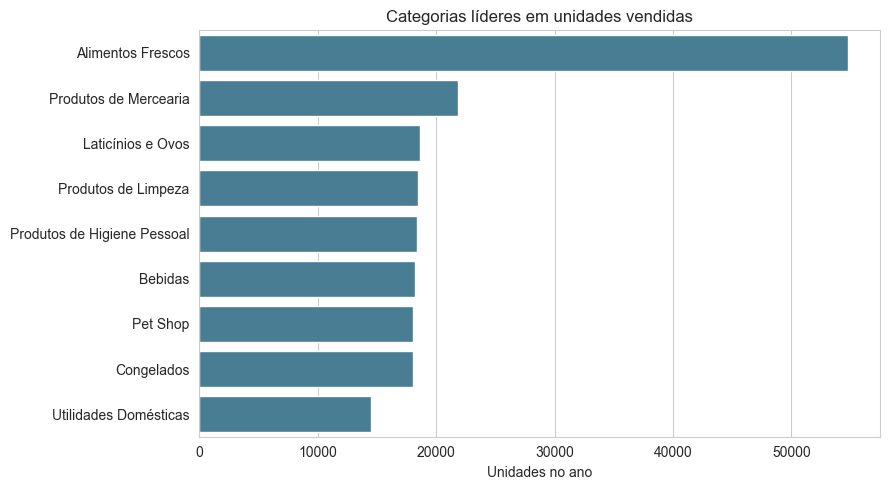

Conclusão: Alimentos Frescos liderou com 54,755 unidades; o mês de pico varia por categoria conforme a tabela acima.


In [45]:
cat_total = df.groupby("Categoria")["Quantidade"].sum().sort_values(ascending=False)
cat_mes = df.groupby(["Categoria", "Mes_nome"], as_index=False)["Quantidade"].sum()
mes_ordem = ["Jan","Fev","Mar","Abr","Mai","Jun","Jul","Ago","Set","Out","Nov","Dez"]
cat_mes["Mes_nome"] = pd.Categorical(cat_mes["Mes_nome"], categories=mes_ordem, ordered=True)
picos = cat_mes.sort_values("Quantidade", ascending=False).groupby("Categoria").head(1)
res = picos.merge(cat_total.rename("Unidades_ano"), on="Categoria").sort_values("Unidades_ano", ascending=False)
display(res.rename(columns={"Quantidade":"Unidades_no_pico","Mes_nome":"Mes_pico"}).reset_index(drop=True))
print("Produtos com maior quantidade anual:")
top_prod = df.groupby("Produto")["Quantidade"].sum().sort_values(ascending=False).head(10)
display(top_prod.rename("Unidades").to_frame())
fig,ax=plt.subplots(figsize=(9,5)); sns.barplot(x=cat_total.head(10).values,y=cat_total.head(10).index,ax=ax,color="#3B82A0")
ax.set(title="Categorias líderes em unidades vendidas",xlabel="Unidades no ano",ylabel=""); plt.tight_layout(); plt.show()
print(f"Conclusão: {cat_total.index[0]} liderou com {cat_total.iloc[0]:,} unidades; o mês de pico varia por categoria conforme a tabela acima.")

Relacao de vinhos por meses:

In [ ]:
import pandas as pd

# Carrega o arquivo CSV
df = pd.read_csv("vendas_supermercado_com_cliente.csv", encoding="utf-8-sig")

# Converte a coluna Data para o formato de data
df["Data"] = pd.to_datetime(df["Data"])

# Filtra as vendas do produto Vinhos
vinhos = df[df["Produto"].str.strip().str.casefold() == "vinhos"].copy()

# Soma a quantidade vendida em cada mês
tabela = (
    vinhos.groupby(vinhos["Data"].dt.month)["Quantidade"]
    .sum()
    .reindex(range(1, 13), fill_value=0)
    .to_frame(name="Quantidade vendida")
)

# Calcula a variação em relação ao mês anterior
tabela["Variação em unidades"] = tabela["Quantidade vendida"].diff()
tabela["Variação percentual"] = tabela["Quantidade vendida"].pct_change() * 100

# Substitui os números dos meses pelos nomes
meses = {
    1: "Janeiro", 2: "Fevereiro", 3: "Março", 4: "Abril",
    5: "Maio", 6: "Junho", 7: "Julho", 8: "Agosto",
    9: "Setembro", 10: "Outubro", 11: "Novembro", 12: "Dezembro"
}
tabela.index = tabela.index.map(meses)
tabela.index.name = "Mês"

tabela

,Quantidade vendida,Variação em unidades,Variação percentual
Mês,,,
Janeiro,323,NaN,NaN
Fevereiro,292,-31.0,-9.597523
Março,281,-11.0,-3.767123
Abril,252,-29.0,-10.320285
Maio,368,116.0,46.031746
Junho,261,-107.0,-29.076087
Julho,336,75.0,28.735632
Agosto,258,-78.0,-23.214286
Setembro,298,40.0,15.503876


meses de maior consumo de vinho foram Janeiro, maio e junho
precisamos saber quem consome mais vinhos por faixa etaria 

In [ ]:
import pandas as pd

df = pd.read_csv("vendas_supermercado_com_cliente.csv", encoding="utf-8-sig")
df["Data"] = pd.to_datetime(df["Data"])

vinhos = df[
    df["Produto"].str.strip().str.casefold() == "vinhos"
].copy()

vinhos["Mês"] = vinhos["Data"].dt.month

tabela = vinhos.groupby("Mês").agg(
    unidades_vendidas=("Quantidade", "sum"),
    idade_media=("Idade", "mean")
)

tabela = tabela.reindex(range(1, 13))

meses = {
    1: "Janeiro", 2: "Fevereiro", 3: "Março", 4: "Abril",
    5: "Maio", 6: "Junho", 7: "Julho", 8: "Agosto",
    9: "Setembro", 10: "Outubro", 11: "Novembro", 12: "Dezembro"
}

tabela.index = tabela.index.map(meses)
tabela.index.name = "Mês"

correlacao = tabela["unidades_vendidas"].corr(tabela["idade_media"])

print(tabela.round(1))
print(f"\nCorrelação entre vendas e idade média: {correlacao:.2f}")


           unidades_vendidas  idade_media
Mês                                      
Janeiro                  323         45.9
Fevereiro                292         53.8
Março                    281         43.2
Abril                    252         45.9
Maio                     368         46.6
Junho                    261         47.7
Julho                    336         44.8
Agosto                   258         41.1
Setembro                 298         43.7
Outubro                  302         45.7
Novembro                 274         45.9
Dezembro                 261         44.5

Correlação entre vendas e idade média: 0.14


In [24]:

df = pd.read_csv("vendas_supermercado_com_cliente.csv", encoding="utf-8-sig")

vinhos = df[
    df["Produto"].str.strip().str.casefold() == "vinhos"
]

idades = vinhos["Idade"].dropna()

print(f"Média: {idades.mean():.2f} anos")
print(f"Mediana: {idades.median():.0f} anos")
print(f"Moda: {idades.mode().tolist()} anos")

Média: 45.67 anos
Mediana: 46 anos
Moda: [54] anos


as pessoas que mais compram vinhos sao as de 54 anos 

In [40]:

df = pd.read_csv("vendas_supermercado_com_cliente.csv", encoding="utf-8-sig")
df["Data"] = pd.to_datetime(df["Data"])
vinhos = df[df["Produto"].str.strip().str.casefold() == "vinhos"].copy()

dias = {0: "Segunda-feira",
    1: "Terça-feira",
    2: "Quarta-feira",
    3: "Quinta-feira",
    4: "Sexta-feira",
    5: "Sábado",
    6: "Domingo",
}
vinhos["Dia da semana"] = vinhos["Data"].dt.dayofweek.map(dias)
tabela = (
    vinhos.groupby("Dia da semana")["Quantidade"]
    .sum()
    .sort_values(ascending=False)
    .rename("Unidades vendidas")
)
tabela

Dia da semana
Domingo          546
Quarta-feira     539
Sexta-feira      495
Terça-feira      493
Quinta-feira     481
Segunda-feira    479
Sábado           473
Name: Unidades vendidas, dtype: int64

temos clientes com idade superior a 54 que compram mais vinhos, nos domingos em meses janeiro, maio e junho.

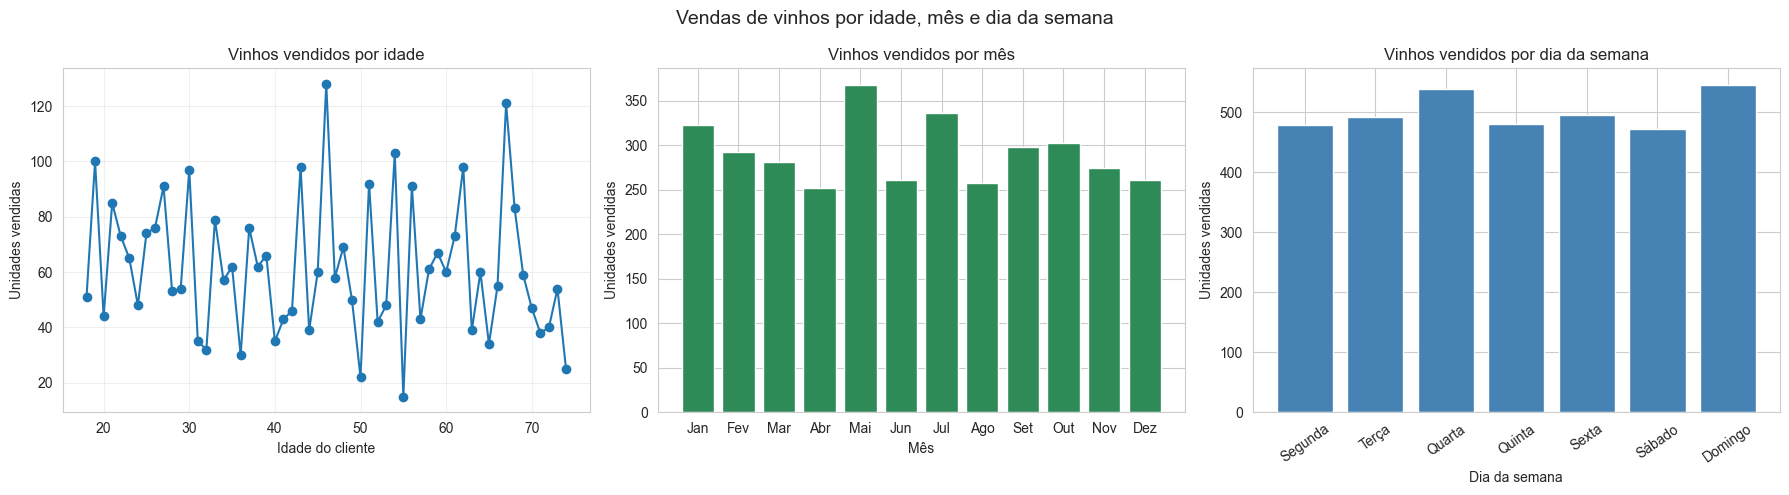

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

# Carregar os dados e preparar as colunas
df = pd.read_csv("vendas_supermercado_com_cliente.csv", encoding="utf-8-sig")
df["Data"] = pd.to_datetime(df["Data"])

# Filtrar somente as vendas de vinhos
vinhos = df[
    df["Produto"].str.strip().str.casefold() == "vinhos"
].copy()

# Criar colunas de mês e dia da semana
nomes_meses = {
    1: "Jan", 2: "Fev", 3: "Mar", 4: "Abr",
    5: "Mai", 6: "Jun", 7: "Jul", 8: "Ago",
    9: "Set", 10: "Out", 11: "Nov", 12: "Dez"
}

nomes_dias = {
    0: "Segunda", 1: "Terça", 2: "Quarta", 3: "Quinta",
    4: "Sexta", 5: "Sábado", 6: "Domingo"
}

vinhos["Mês"] = vinhos["Data"].dt.month.map(nomes_meses)
vinhos["Dia da semana"] = vinhos["Data"].dt.dayofweek.map(nomes_dias)

# Somar a quantidade de vinhos vendida por idade, mês e dia da semana
vendas_por_idade = vinhos.groupby("Idade")["Quantidade"].sum().sort_index()

ordem_meses = list(nomes_meses.values())
vendas_por_mes = (
    vinhos.groupby("Mês")["Quantidade"]
    .sum()
    .reindex(ordem_meses, fill_value=0)
)

ordem_dias = list(nomes_dias.values())
vendas_por_dia = (
    vinhos.groupby("Dia da semana")["Quantidade"]
    .sum()
    .reindex(ordem_dias, fill_value=0)
)

# Criar os três gráficos
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(vendas_por_idade.index, vendas_por_idade.values, marker="o")
axes[0].set_title("Vinhos vendidos por idade")
axes[0].set_xlabel("Idade do cliente")
axes[0].set_ylabel("Unidades vendidas")
axes[0].grid(True, alpha=0.3)

axes[1].bar(vendas_por_mes.index, vendas_por_mes.values, color="seagreen")
axes[1].set_title("Vinhos vendidos por mês")
axes[1].set_xlabel("Mês")
axes[1].set_ylabel("Unidades vendidas")

axes[2].bar(vendas_por_dia.index, vendas_por_dia.values, color="steelblue")
axes[2].set_title("Vinhos vendidos por dia da semana")
axes[2].set_xlabel("Dia da semana")
axes[2].set_ylabel("Unidades vendidas")
axes[2].tick_params(axis="x", rotation=35)

fig.suptitle("Vendas de vinhos por idade, mês e dia da semana", fontsize=14)
plt.tight_layout()
plt.show()

## 2. Média de vendas diárias por categoria

Somam-se os valores de venda por categoria em cada data e calcula-se a média diária ao longo do período.

,Venda_media_diaria
Categoria,
Alimentos Frescos,3740.573855
Produtos de Mercearia,1451.105881
Laticínios e Ovos,1260.165676
Bebidas,1244.915513
Produtos de Limpeza,1226.153029
Pet Shop,1206.387844
Produtos de Higiene Pessoal,1205.587619
Congelados,1204.712693
Utilidades Domésticas,984.993361


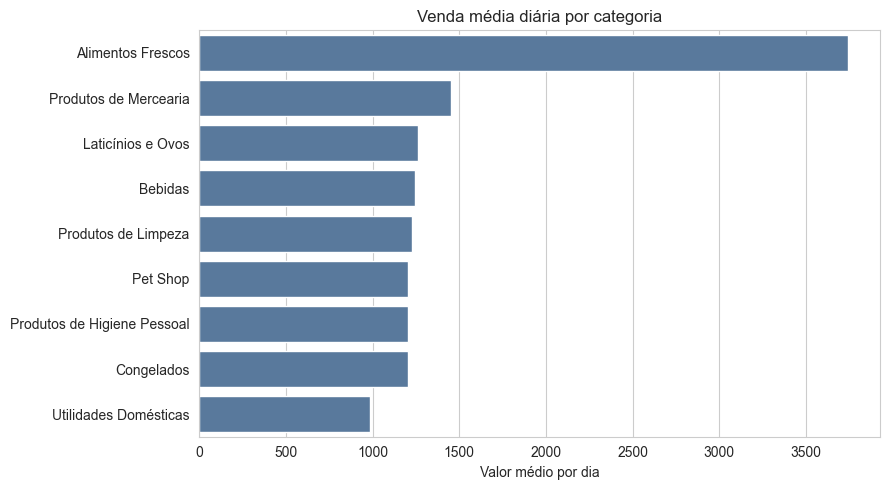

Conclusão: Alimentos Frescos teve a maior venda média diária (3,740.57).


In [4]:
por_dia_cat = df.groupby(["Data", "Categoria"]).agg(Venda_do_dia=("Total_Venda","sum")).reset_index()
media_diaria_cat = por_dia_cat.groupby("Categoria")["Venda_do_dia"].mean().sort_values(ascending=False)
display(media_diaria_cat.rename("Venda_media_diaria").to_frame())
fig,ax=plt.subplots(figsize=(9,5)); sns.barplot(x=media_diaria_cat.values,y=media_diaria_cat.index,ax=ax,color="#4E79A7")
ax.set(title="Venda média diária por categoria",xlabel="Valor médio por dia",ylabel=""); plt.tight_layout(); plt.show()
print(f"Conclusão: {media_diaria_cat.idxmax()} teve a maior venda média diária ({media_diaria_cat.max():,.2f}).")


## 3. Sazonalidade dos produtos

A sazonalidade é estimada pelo coeficiente de variação (CV = desvio-padrão/média) das quantidades mensais de cada produto. CV alto indica maior variação relativa entre meses; com apenas um ano, não comprova um padrão sazonal recorrente.

,Produto,mean,std,CV_mensal,Menor_mes,Maior_mes
13,Croissants,305.166667,47.615569,0.156031,Abr,Mar
43,Sabão em pó,309.500000,45.707568,0.147682,Mai,Ago
28,Ovos,313.166667,43.228428,0.138036,Fev,Dez
37,Pão integral,305.000000,41.880783,0.137314,Fev,Mar
33,Pratos prontos congelados,303.000000,41.314756,0.136352,Fev,Jul
35,"Produtos descartáveis (pratos, copos, talheres)",290.166667,37.030291,0.127617,Nov,Out
45,Shampoos,306.500000,39.006992,0.127266,Fev,Ago
42,Sabonetes,308.500000,38.979015,0.126350,Nov,Jul
16,Esponjas,302.000000,37.670823,0.124738,Nov,Mai
52,Vinhos,292.166667,35.588132,0.121808,Abr,Mai


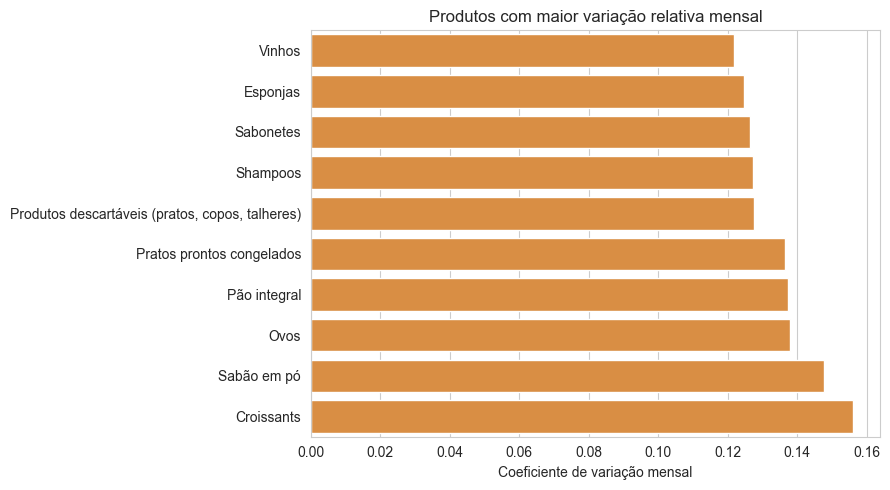

Conclusão: Croissants teve o maior CV mensal (15.6%). Com apenas um ano, isso mede variação dentro do ano, não recorrência sazonal.


In [5]:
prod_mes = df.groupby(["Produto", "Mes"]).agg(Quantidade_mensal=("Quantidade","sum")).reset_index()
sazonal = prod_mes.groupby("Produto")["Quantidade_mensal"].agg(["mean","std"])
sazonal["CV_mensal"] = sazonal["std"] / sazonal["mean"]
extremos = prod_mes.sort_values("Quantidade_mensal").groupby("Produto").agg(Menor_mes=("Mes","first"),Maior_mes=("Mes","last")).reset_index()
sazonal = pd.merge(sazonal.reset_index(),extremos,on="Produto")
sazonal["Menor_mes"] = sazonal["Menor_mes"].apply(lambda mes: meses[mes])
sazonal["Maior_mes"] = sazonal["Maior_mes"].apply(lambda mes: meses[mes])
display(sazonal.sort_values("CV_mensal", ascending=False).head(15))
top_cv=sazonal.sort_values("CV_mensal",ascending=False).head(10).sort_values("CV_mensal").set_index("Produto")
fig,ax=plt.subplots(figsize=(9,5)); sns.barplot(x=top_cv.CV_mensal.values,y=top_cv.index,ax=ax,color="#F28E2B")
ax.set(title="Produtos com maior variação relativa mensal",xlabel="Coeficiente de variação mensal",ylabel=""); plt.tight_layout(); plt.show()
print(f"Conclusão: {sazonal.sort_values('CV_mensal',ascending=False).iloc[0]['Produto']} teve o maior CV mensal ({sazonal['CV_mensal'].max():.1%}). Com apenas um ano, isso mede variação dentro do ano, não recorrência sazonal.")

## 4. Faixas etárias com maior contribuição às vendas

Faixas conforme o enunciado: jovem (18–35), adulto (36–59) e idoso (60 anos ou mais). A faixa idoso inclui 60 anos para não deixar essa idade sem classificação.

,Venda_total,Registros,Idade_media,Participacao
Faixa_etaria,,,,
Adulto (36–59),2.102042e+06,8483,47.641872,0.425818
Idoso (60+),1.297252e+06,5245,67.032412,0.262789
Jovem (18–35),1.537183e+06,6347,26.402237,0.311393


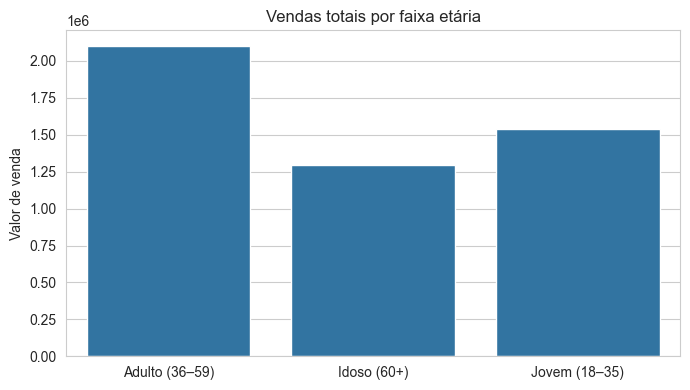

Conclusão: Adulto (36–59) contribuiu mais para a receita (42.6% do total).


In [6]:
def classificar_idade(idade):
    if idade <= 35:
        return "Jovem (18–35)"
    elif idade <= 59:
        return "Adulto (36–59)"
    else:
        return "Idoso (60+)"
df["Faixa_etaria"] = df["Idade"].apply(classificar_idade)
faixa_vendas = df.groupby("Faixa_etaria").agg(Venda_total=("Total_Venda","sum"), Registros=("Total_Venda","count"), Idade_media=("Idade","mean"))
faixa_vendas["Participacao"] = faixa_vendas["Venda_total"] / df["Total_Venda"].sum()
display(faixa_vendas)
fig,ax=plt.subplots(figsize=(7,4)); sns.barplot(x=faixa_vendas.index.astype(str),y=faixa_vendas.Venda_total.values,ax=ax)
ax.set(title="Vendas totais por faixa etária",ylabel="Valor de venda",xlabel=""); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
lider_faixa=faixa_vendas.Venda_total.idxmax(); print(f"Conclusão: {lider_faixa} contribuiu mais para a receita ({faixa_vendas.loc[lider_faixa,'Participacao']:.1%} do total).")

## 5. Relação entre idade e categoria mais vendida

Para cada faixa, a categoria líder é definida pela soma de unidades; a tabela também mostra sua participação nas unidades da faixa.

,Faixa_etaria,Categoria,Unidades,Venda,Unidades_faixa,Participacao_unidades_faixa
0,Adulto (36–59),Alimentos Frescos,23212,588500.6163,85009,0.273053
9,Idoso (60+),Alimentos Frescos,14365,361577.6914,52340,0.274455
18,Jovem (18–35),Alimentos Frescos,17178,415231.1493,63555,0.270286


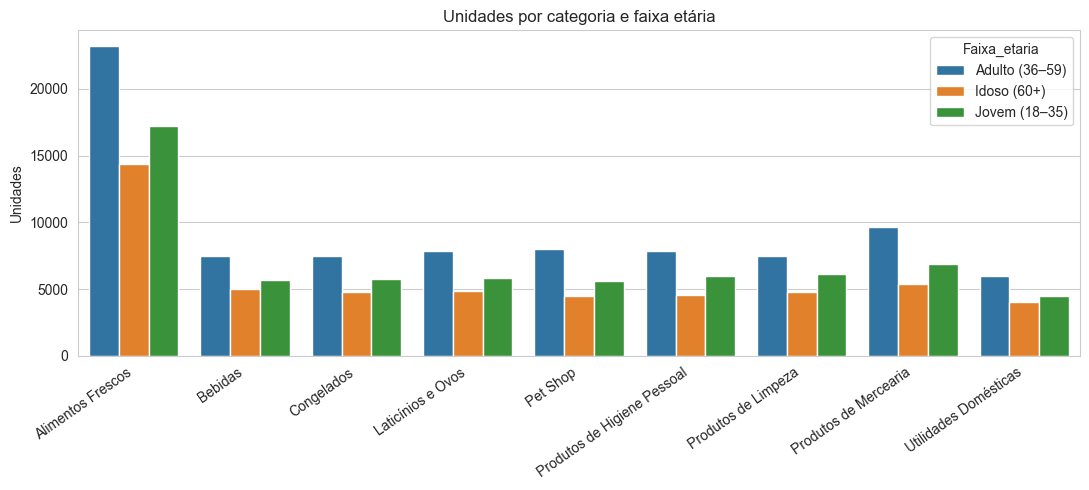

Conclusão — categoria líder por faixa: Jovem: Alimentos Frescos; Adulto: Alimentos Frescos; Idoso: Alimentos Frescos.


In [7]:
faixa_cat = df.groupby(["Faixa_etaria","Categoria"]).agg(Unidades=("Quantidade","sum"), Venda=("Total_Venda","sum")).reset_index()
totais_faixa = faixa_cat.groupby("Faixa_etaria").agg(Unidades_faixa=("Unidades","sum")).reset_index()
faixa_cat = pd.merge(faixa_cat,totais_faixa,on="Faixa_etaria")
faixa_cat["Participacao_unidades_faixa"] = faixa_cat["Unidades"] / faixa_cat["Unidades_faixa"]
lideres = faixa_cat.loc[faixa_cat.groupby("Faixa_etaria")["Unidades"].idxmax()].sort_values("Faixa_etaria")
display(lideres)
fig,ax=plt.subplots(figsize=(11,5)); sns.barplot(data=faixa_cat,x="Categoria",y="Unidades",hue="Faixa_etaria",ax=ax)
ax.set(title="Unidades por categoria e faixa etária",ylabel="Unidades",xlabel=""); plt.xticks(rotation=35,ha="right"); plt.tight_layout(); plt.show()
lider_jovem=lideres[lideres["Faixa_etaria"]=="Jovem (18–35)"].iloc[0]["Categoria"]
lider_adulto=lideres[lideres["Faixa_etaria"]=="Adulto (36–59)"].iloc[0]["Categoria"]
lider_idoso=lideres[lideres["Faixa_etaria"]=="Idoso (60+)"].iloc[0]["Categoria"]
print(f"Conclusão — categoria líder por faixa: Jovem: {lider_jovem}; Adulto: {lider_adulto}; Idoso: {lider_idoso}.")

a faixa de adultos superios a 36 anos é a economicamente mais ativa, o que faz bastante sentido
propocionalmente os adultos e jovem sempre irao gastar mais 

## 6. Distribuição das vendas por dia da semana

Compara-se a média de venda diária total por dia da semana, evitando que meses com mais ocorrências de um dia distorçam o total.

,Media_diaria,Total,Dias
Dia_semana_nome,,,
Segunda,13380.332946,695777.3132,52
Terça,13197.652610,686277.9357,52
Quarta,13654.846446,710052.0152,52
Quinta,13582.906342,706311.1298,52
Sexta,13601.748206,707290.9067,52
Sábado,13615.084058,707984.3710,52
Domingo,13637.427836,722783.6753,53


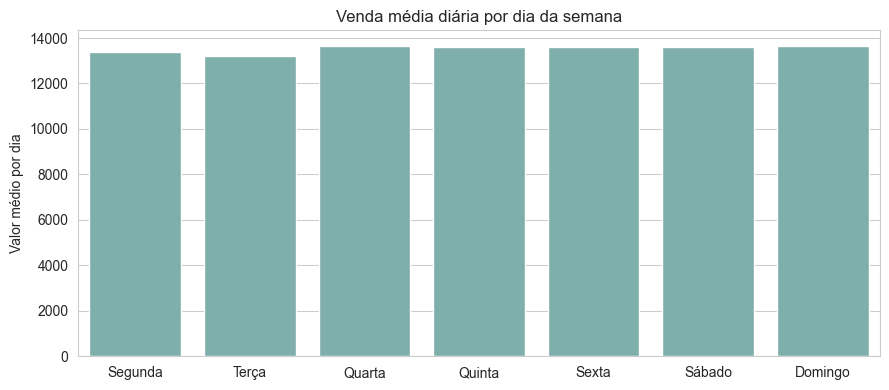

Conclusão: Quarta teve a maior média diária (13,654.85) e Terça a menor (13,197.65).


In [8]:
dia = df.groupby(["Data","Dia_semana_nome"])["Total_Venda"].sum().reset_index()
ordem_dias = ["Segunda","Terça","Quarta","Quinta","Sexta","Sábado","Domingo"]
dist_dia = dia.groupby("Dia_semana_nome")["Total_Venda"].agg(Media_diaria="mean", Total="sum", Dias="count").reindex(ordem_dias)
display(dist_dia)
fig,ax=plt.subplots(figsize=(9,4)); sns.barplot(x=dist_dia.index,y=dist_dia.Media_diaria.values,ax=ax,color="#76B7B2")
ax.set(title="Venda média diária por dia da semana",ylabel="Valor médio por dia",xlabel=""); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
mais_forte=dist_dia.Media_diaria.idxmax(); mais_fraco=dist_dia.Media_diaria.idxmin()
print(f"Conclusão: {mais_forte} teve a maior média diária ({dist_dia.loc[mais_forte,'Media_diaria']:,.2f}) e {mais_fraco} a menor ({dist_dia.loc[mais_fraco,'Media_diaria']:,.2f}).")


## 7. Vendas mensais antes e durante a Black Friday

Como a Black Friday de 2023 ocorreu em 24 de novembro, “durante” é representado por novembro completo; janeiro a outubro representam o período anterior. A média diária ajuda a comparar meses com quantidades diferentes de dias.

,Mes_nome,Venda_total,Venda_media_diaria,Unidades,Periodo
0,Jan,436669.7100,14086.119677,16980,Antes (jan–out)
1,Fev,400993.0700,14321.181071,15275,Antes (jan–out)
2,Mar,434595.1800,14019.199355,17133,Antes (jan–out)
3,Abr,389706.5733,12990.219110,16551,Antes (jan–out)
4,Mai,381634.9586,12310.805116,16832,Antes (jan–out)
5,Jun,419441.5500,13981.385000,16674,Antes (jan–out)
6,Jul,449736.7700,14507.637742,17288,Antes (jan–out)
7,Ago,402805.9462,12993.740200,16934,Antes (jan–out)
8,Set,406676.5800,13555.886000,16407,Antes (jan–out)
9,Out,416884.8516,13447.898439,17269,Antes (jan–out)


Média diária jan–out: 13,621.41 | novembro: 12,858.11 | variação: -5.6%


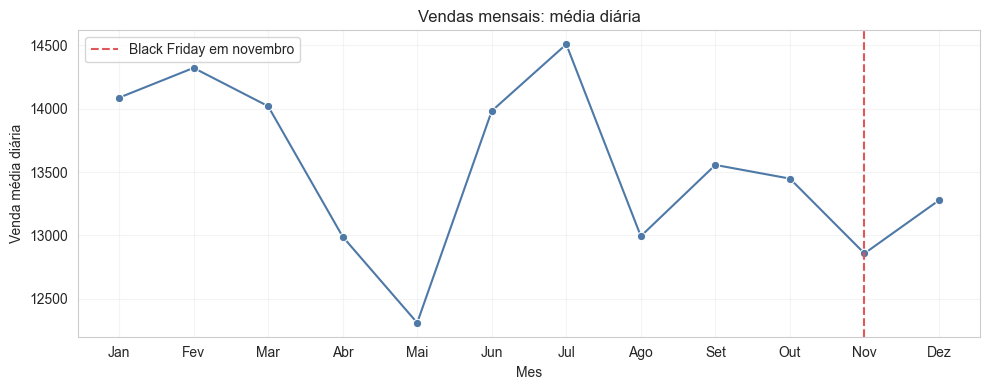

Conclusão: novembro ficou 5.6% abaixo da média diária de janeiro a outubro.


In [9]:
mensal = df.groupby(["Mes","Mes_nome"]).agg(Venda_total=("Total_Venda","sum"), Unidades=("Quantidade","sum"), Registros=("Total_Venda","size")).reset_index()
mensal["Venda_media_diaria"] = mensal["Venda_total"] / mensal["Data"].nunique() if "Data" in mensal else mensal["Venda_total"] / df.groupby("Mes")["Data"].nunique().values
def classificar_periodo(mes):
    if mes < 11:
        return "Antes (jan–out)"
    elif mes == 11:
        return "Mês da Black Friday (nov)"
    else:
        return "Após (dez)"
mensal["Periodo"] = mensal["Mes"].apply(classificar_periodo)
display(mensal[["Mes_nome","Venda_total","Venda_media_diaria","Unidades","Periodo"]])
antes = mensal.loc[mensal.Mes<11,"Venda_media_diaria"].mean(); novembro = mensal.loc[mensal.Mes==11,"Venda_media_diaria"].iloc[0]
print(f"Média diária jan–out: {antes:,.2f} | novembro: {novembro:,.2f} | variação: {(novembro/antes-1):+.1%}")
fig,ax=plt.subplots(figsize=(10,4)); sns.lineplot(data=mensal,x="Mes",y="Venda_media_diaria",marker="o",ax=ax,color="#4E79A7")
ax.axvline(11,color="#E15759",linestyle="--",label="Black Friday em novembro"); ax.set_xticks(range(1,13),mes_ordem)
ax.set_ylabel("Venda média diária"); ax.set_title("Vendas mensais: média diária"); ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()
print(f"Conclusão: novembro ficou {abs(novembro/antes-1):.1%} {'acima' if novembro>antes else 'abaixo'} da média diária de janeiro a outubro.")

## 8. Ticket médio por faixa etária e categoria

Sem identificador de compra, usamos a média de `Total_Venda` por linha como **valor médio por registro de produto**. Essa medida não deve ser interpretada como ticket por cliente ou cesta.

,Faixa_etaria,Categoria,Ticket_medio_registro
0,Adulto (36–59),Alimentos Frescos,253.664059
1,Adulto (36–59),Bebidas,240.421985
2,Adulto (36–59),Congelados,245.670753
3,Adulto (36–59),Laticínios e Ovos,249.264281
4,Adulto (36–59),Pet Shop,247.798387
5,Adulto (36–59),Produtos de Higiene Pessoal,244.521748
6,Adulto (36–59),Produtos de Limpeza,249.264331
7,Adulto (36–59),Produtos de Mercearia,242.295457
8,Adulto (36–59),Utilidades Domésticas,246.394274
9,Idoso (60+),Alimentos Frescos,251.970517


Média geral por faixa etária (valor por registro):


,Valor_medio_por_registro
Faixa_etaria,
Adulto (36–59),247.794621
Idoso (60+),247.331211
Jovem (18–35),242.190543


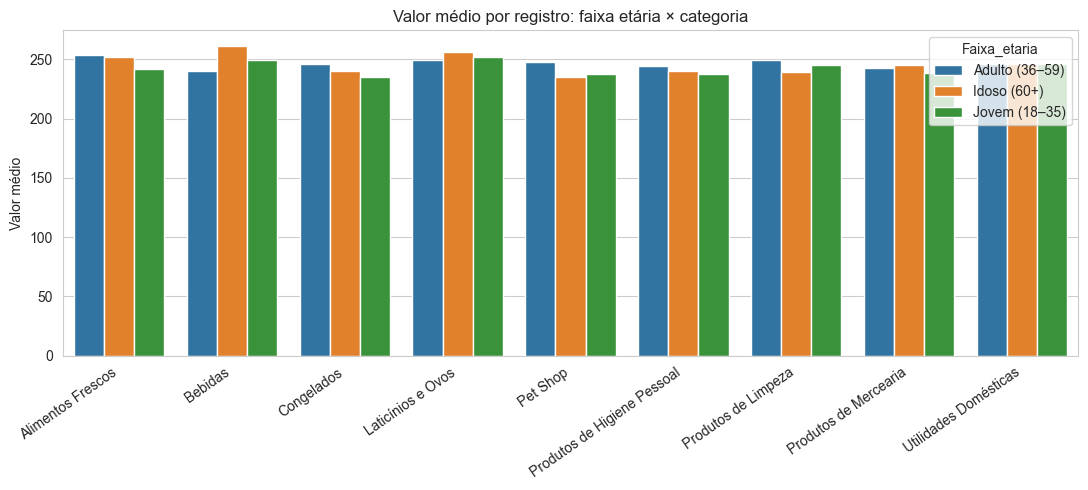

Conclusão: maior valor médio por registro em Idoso (60+) / Bebidas (261.24).


In [10]:
ticket = df.groupby(["Faixa_etaria","Categoria"]).agg(Ticket_medio_registro=("Total_Venda","mean")).reset_index()
display(ticket)
print("Média geral por faixa etária (valor por registro):")
display(df.groupby("Faixa_etaria").agg(Valor_medio_por_registro=("Total_Venda","mean")))
fig,ax=plt.subplots(figsize=(11,5)); sns.barplot(data=ticket,x="Categoria",y="Ticket_medio_registro",hue="Faixa_etaria",ax=ax)
ax.set_title("Valor médio por registro: faixa etária × categoria"); ax.set_xlabel(""); ax.set_ylabel("Valor médio"); plt.xticks(rotation=35,ha="right"); plt.tight_layout(); plt.show()
maior_ticket=ticket.sort_values("Ticket_medio_registro",ascending=False).iloc[0]
print(f"Conclusão: maior valor médio por registro em {maior_ticket['Faixa_etaria']} / {maior_ticket['Categoria']} ({maior_ticket['Ticket_medio_registro']:,.2f}).")

## 9. Semana da Black Friday versus semana do Natal

Compara-se a semana calendário de segunda a domingo que contém cada data: 20–26/11/2023 e 25–31/12/2023. Indicador principal: venda média diária total da loja.

,Venda_total,Media_diaria
Black Friday,76452.0798,10921.725686
Natal,81146.6127,11592.373243


Maior média diária: Natal (11,592.37).


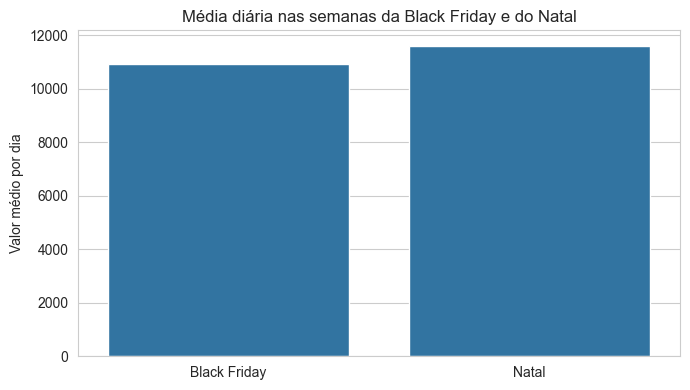

Conclusão: a semana de Natal superou a outra em 670.65 por dia, em média.


In [11]:
bf_semana = df[df["Data"].between("2023-11-20","2023-11-26")]
natal_semana = df[df["Data"].between("2023-12-25","2023-12-31")]
bf_por_dia = bf_semana.groupby("Data").agg(Venda_diaria=("Total_Venda","sum"))
natal_por_dia = natal_semana.groupby("Data").agg(Venda_diaria=("Total_Venda","sum"))
comp = pd.DataFrame({"Venda_total":[bf_por_dia["Venda_diaria"].sum(),natal_por_dia["Venda_diaria"].sum()],
                     "Media_diaria":[bf_por_dia["Venda_diaria"].mean(),natal_por_dia["Venda_diaria"].mean()]},
                    index=["Black Friday","Natal"])
display(comp)
vencedora=comp.Media_diaria.idxmax(); print(f"Maior média diária: {vencedora} ({comp.loc[vencedora,'Media_diaria']:,.2f}).")
fig,ax=plt.subplots(figsize=(7,4)); sns.barplot(x=comp.index,y=comp.Media_diaria.values,ax=ax)
ax.set(title="Média diária nas semanas da Black Friday e do Natal",ylabel="Valor médio por dia",xlabel=""); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
print(f"Conclusão: a semana de {vencedora} superou a outra em {abs(comp.Media_diaria.iloc[0]-comp.Media_diaria.iloc[1]):,.2f} por dia, em média.")

## 10. Impacto observado dos descontos e produtos com maior aumento

Promoção é qualquer registro com desconto maior que zero. O efeito é descritivo: compara registros promocionais e sem promoção. O aumento por produto usa quantidade média diária nos dias em que houve desconto no produto versus os demais dias; exige ao menos um dia em cada grupo.

,Promocao,Registros,Desconto_medio,Quantidade_media,Venda_media,Venda_soma
Situacao,,,,,,
Sem desconto,False,15895,0.000000,10.012394,256.414571,4.075710e+06
Com desconto,True,4180,0.190955,9.989713,205.925298,8.607677e+05


,Qtd_com_promocao,Qtd_sem_promocao,Aumento_qtd_media_%
Produto,,,
Frango,11.381579,9.989619,13.934060
Farinha,11.052632,9.813149,12.630837
Bananas,10.328947,9.328720,10.722025
Azeite,10.802632,9.813149,10.083234
Talheres,11.131579,10.176471,9.385458
Maçãs,11.026316,10.155709,8.572581
Tilápia,10.460526,9.681661,8.044750
Papel higiênico,10.684211,9.937716,7.511728
Salmão,10.486842,9.851211,6.452314


Interpretação: diferença observacional; não é possível afirmar causalidade.


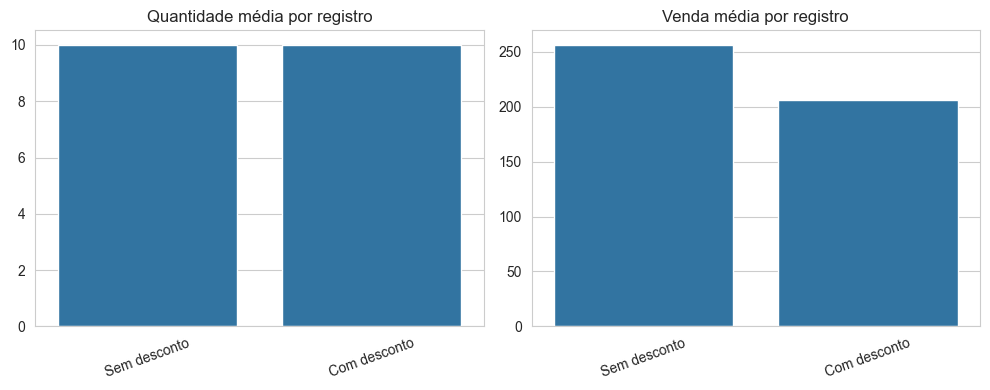

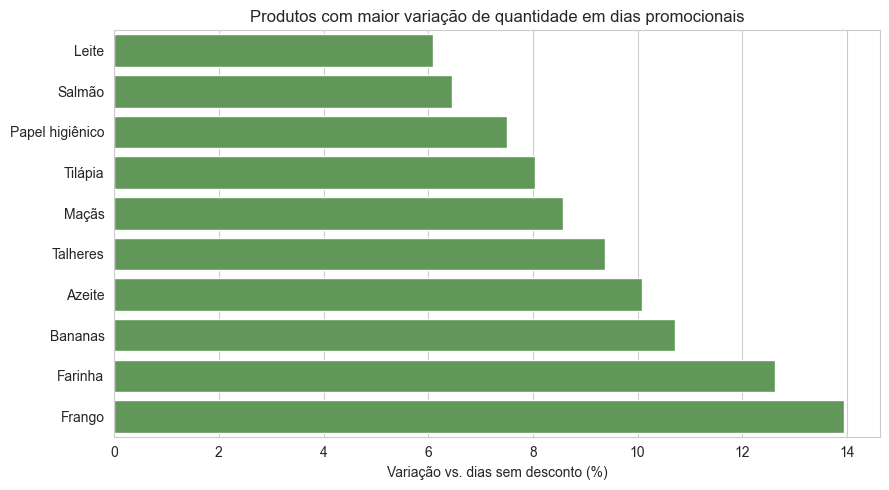

Conclusão: a quantidade média por registro foi 0.02 unidades menor em registros promocionais. Frango teve a maior alta estimada (+13.9%). Associação descritiva, não causal.


In [12]:
impacto = df.groupby("Promocao").agg(Registros=("Total_Venda","size"), Desconto_medio=("Desconto","mean"), Quantidade_media=("Quantidade","mean"), Venda_media=("Total_Venda","mean"), Venda_soma=("Total_Venda","sum"))
impacto = impacto.reset_index()
impacto["Situacao"] = impacto["Promocao"].apply(lambda promocao: "Com desconto" if promocao else "Sem desconto")
impacto = impacto.set_index("Situacao")
display(impacto)
com_promocao = df[df["Promocao"]].groupby("Produto").agg(Qtd_com_promocao=("Quantidade","mean")).reset_index()
sem_promocao = df[~df["Promocao"]].groupby("Produto").agg(Qtd_sem_promocao=("Quantidade","mean")).reset_index()
por_prod = pd.merge(com_promocao,sem_promocao,on="Produto")
por_prod["Aumento_qtd_media_%"] = (por_prod["Qtd_com_promocao"] / por_prod["Qtd_sem_promocao"] - 1) * 100
por_prod = por_prod.set_index("Produto")
display(por_prod.sort_values("Aumento_qtd_media_%",ascending=False).head(15))
print("Interpretação: diferença observacional; não é possível afirmar causalidade.")
fig,axes=plt.subplots(1,2,figsize=(10,4))
sns.barplot(x=impacto.index,y=impacto["Quantidade_media"].values,ax=axes[0]); axes[0].set_title("Quantidade média por registro")
sns.barplot(x=impacto.index,y=impacto["Venda_media"].values,ax=axes[1]); axes[1].set_title("Venda média por registro")
for ax in axes: ax.set_xlabel(""); ax.tick_params(axis="x",rotation=20)
plt.tight_layout(); plt.show()
melhor=por_prod.sort_values("Aumento_qtd_media_%",ascending=False).head(10).sort_values("Aumento_qtd_media_%")
fig,ax=plt.subplots(figsize=(9,5)); sns.barplot(x=melhor["Aumento_qtd_media_%"].values,y=melhor.index,ax=ax,color="#59A14F")
ax.set(title="Produtos com maior variação de quantidade em dias promocionais",xlabel="Variação vs. dias sem desconto (%)",ylabel=""); plt.tight_layout(); plt.show()
delta=impacto.loc["Com desconto","Quantidade_media"]-impacto.loc["Sem desconto","Quantidade_media"]
print(f"Conclusão: a quantidade média por registro foi {abs(delta):.2f} unidades {'maior' if delta>0 else 'menor' if delta<0 else 'igual'} em registros promocionais. {por_prod['Aumento_qtd_media_%'].idxmax()} teve a maior alta estimada ({por_prod['Aumento_qtd_media_%'].max():+.1f}%). Associação descritiva, não causal.")

In [49]:
resumo = df.groupby("Categoria").agg(
    faturamento=("Total_Venda", "sum"),
    produtos=("Produto", "nunique")
)
resumo["faturamento_por_produto"] = resumo["faturamento"] / resumo["produtos"]
resumo.sort_values("faturamento_por_produto", ascending=False)


def formatar_reais(valor):
    return f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

resumo_formatado = resumo.copy()
for coluna in ["faturamento", "faturamento_por_produto"]:
    resumo_formatado[coluna] = resumo_formatado[coluna].apply(formatar_reais)

display(resumo_formatado)

,faturamento,produtos,faturamento_por_produto
Categoria,,,
Alimentos Frescos,"R$ 1.365.309,46",15,"R$ 91.020,63"
Bebidas,"R$ 454.394,16",5,"R$ 90.878,83"
Congelados,"R$ 439.720,13",5,"R$ 87.944,03"
Laticínios e Ovos,"R$ 459.960,47",5,"R$ 91.992,09"
Pet Shop,"R$ 440.331,56",5,"R$ 88.066,31"
Produtos de Higiene Pessoal,"R$ 440.039,48",5,"R$ 88.007,90"
Produtos de Limpeza,"R$ 447.545,86",5,"R$ 89.509,17"
Produtos de Mercearia,"R$ 529.653,65",6,"R$ 88.275,61"
Utilidades Domésticas,"R$ 359.522,58",4,"R$ 89.880,64"


In [54]:
##Alguns Insights

# Faturamento médio por dia do mês
df["Data"] = pd.to_datetime(df["Data"])
df["Mes"] = df["Data"].dt.month

por_mes = df.groupby("Mes").agg(
    faturamento=("Total_Venda", "sum"),
    dias=("Data", "nunique")
)
por_mes["media_por_dia"] = por_mes["faturamento"] / por_mes["dias"]

# Faturamento médio por dia da semana
df["Dia_semana"] = df["Data"].dt.day_name()

por_dia_semana = df.groupby("Dia_semana").agg(
    faturamento=("Total_Venda", "sum"),
    dias=("Data", "nunique")
)
por_dia_semana["media_por_dia"] = (
    por_dia_semana["faturamento"] / por_dia_semana["dias"]
)

# Comparação entre dias promocionais e não promocionais
por_data = df.groupby("Data").agg(
    faturamento=("Total_Venda", "sum"),
    quantidade=("Quantidade", "sum"),
    promocao=("Desconto", lambda descontos: (descontos > 0).all())
)

comparacao_promocao = por_data.groupby("promocao").agg(
    dias=("faturamento", "size"),
    faturamento_medio=("faturamento", "mean"),
    quantidade_media=("quantidade", "mean")
)

display(por_mes)
display(por_dia_semana)
display(comparacao_promocao)

,faturamento,dias,media_por_dia
Mes,,,
1,436669.7100,31,14086.119677
2,400993.0700,28,14321.181071
3,434595.1800,31,14019.199355
4,389706.5733,30,12990.219110
5,381634.9586,31,12310.805116
6,419441.5500,30,13981.385000
7,449736.7700,31,14507.637742
8,402805.9462,31,12993.740200
9,406676.5800,30,13555.886000


,faturamento,dias,media_por_dia
Dia_semana,,,
Friday,707290.9067,52,13601.748206
Monday,695777.3132,52,13380.332946
Saturday,707984.3710,52,13615.084058
Sunday,722783.6753,53,13637.427836
Thursday,706311.1298,52,13582.906342
Tuesday,686277.9357,52,13197.652610
Wednesday,710052.0152,52,13654.846446


,dias,faturamento_medio,quantidade_media
promocao,,,
False,289,14102.801384,550.681661
True,76,11325.891407,549.434211


## Conclusao parcial:
1. O faturamento varia mais por mês do que por dia da semana
Calculando o faturamento médio por dia do mês — assim fevereiro não é comparado diretamente com meses mais longos —, julho teve a maior média, R$ 14.507,64 por dia, e maio, a menor, R$ 12.310,81. A diferença é de aproximadamente 17,8%.

Por dia da semana, a variação é bem menor: a média vai de R$ 13.197,65 às terças a R$ 13.654,85 às quartas, cerca de 3,5%. Ou seja, a diferença entre dias da semana parece pequena diante da variação mensal.

2. Os dias de promoção coincidem com descontos em todos os produtos
Em 76 dos 365 dias, todos os 55 produtos aparecem com desconto; nos outros 289 dias, nenhum aparece com desconto. Isso sugere que a coluna Desconto marca dias de promoção geral, e não ofertas independentes por produto.

Nos dias promocionais, o faturamento médio foi R$ 11.325,89 por dia, contra R$ 14.102,80 nos demais dias. A quantidade média vendida ficou muito parecida: cerca de 549 unidades nos dias promocionais e 551 nos outros. Isso não prova que as promoções reduziram as vendas: os descontos diminuem o valor recebido, e a comparação não controla outras diferenças entre as datas. É mais adequado apresentar como associação observada, não como efeito causal.

3. Há pouca distância entre o produto de maior e o de menor faturamento
O produto com maior faturamento anual foi Panelas, com R$ 97.336,01; o menor foi Tilápia, com R$ 84.122,24. A diferença é de aproximadamente 15,7%. Isso sugere que, neste conjunto, o faturamento anual está relativamente distribuído entre os produtos — embora faturamento, sozinho, não mostre lucro ou margem.

## Conclusão Final
uma ressalva sobre os dados: há exatamente 55 registros por dia, um para cada um dos 55 produtos. Isso sugere que a tabela está organizada como produto por dia, e não como compras individuais de clientes. Sem um identificador de cliente, não é seguro concluir, por exemplo, que determinada faixa etária ou renda gasta mais.

Sobre os dias da semana, a diferença média entre o maior e o menor faturamento diário é pequena, em torno de 3,5%. Portanto, o domingo ter mais registros no total não significa necessariamente que as vendas sejam muito maiores nesse dia.

As tabelas e gráficos acima mostram os resultados por categoria, produto, período e faixa etária. Na interpretacao dos resultados, a base contém registros agregados por produto e data, cobre somente um ano e não informa moeda ( eu coloquei como Reais) nem transações/cliente identificável. Portanto, padrões temporais e relações com descontos devem ser tratados como evidência descritiva para orientar investigações, não como estimativas causais.

Insight 
 “Alimentos Frescos” tem o maior faturamento total — 27,7% —, mas também tem 15 produtos, enquanto as demais categorias têm de 4 a 6. Ao comparar o faturamento médio por produto, as categorias ficam bem próximas: cerca de R$88mil a R$92 mil por produto no ano. Então, não dá para concluir que Alimentos Frescos vende muito mais por produto; parte da liderança vem de ter mais produtos na categoria.

## graficos das conclusões

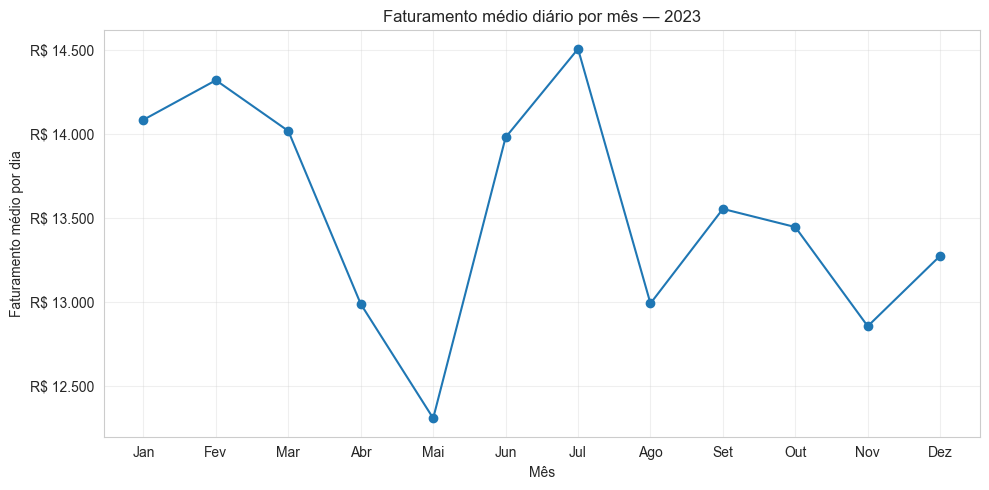

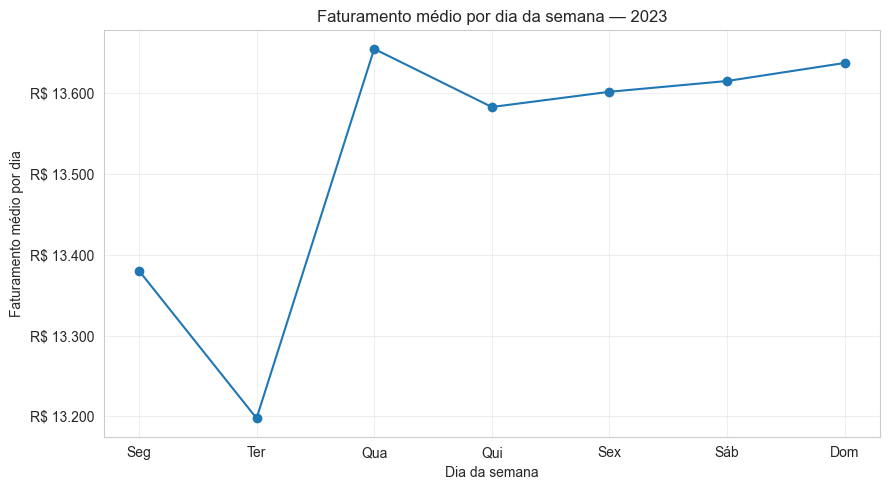

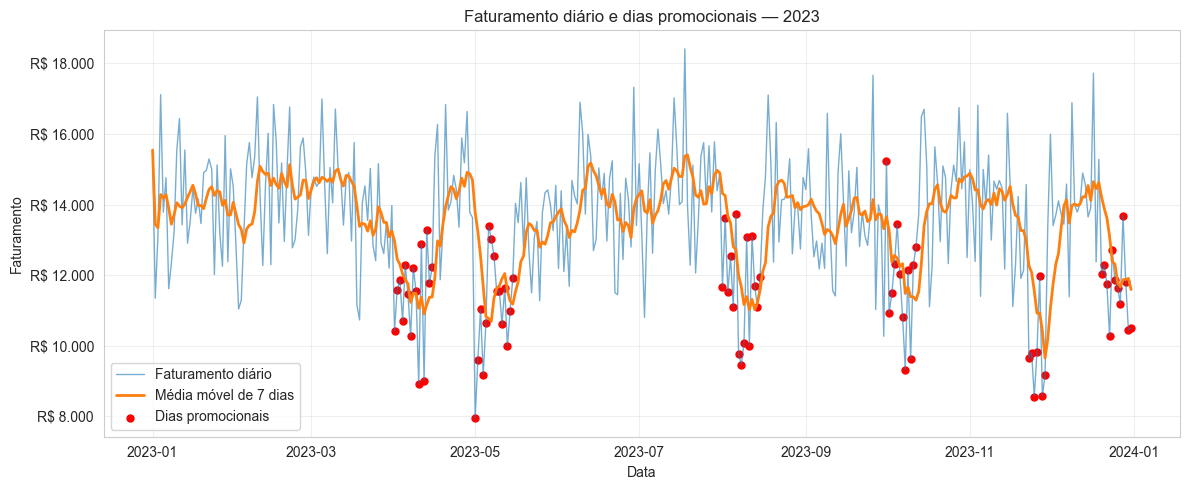

In [55]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Preparação
df["Data"] = pd.to_datetime(df["Data"])

def formatar_reais(valor, _):
    return f"R$ {valor:,.0f}".replace(",", "X").replace(".", ",").replace("X", ".")

meses = [
    "Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
    "Jul", "Ago", "Set", "Out", "Nov", "Dez"
]
dias_semana = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]

# Soma as vendas de todos os produtos em cada data
vendas_diarias = (
    df.groupby("Data")
      .agg(
          faturamento=("Total_Venda", "sum"),
          promocao=("Desconto", lambda descontos: (descontos > 0).all())
      )
      .reset_index()
)

vendas_diarias["Mes"] = vendas_diarias["Data"].dt.month
vendas_diarias["Dia_semana"] = vendas_diarias["Data"].dt.dayofweek

# 1. Faturamento médio por dia em cada mês
media_mensal = vendas_diarias.groupby("Mes")["faturamento"].mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(media_mensal.index, media_mensal.values, marker="o")
ax.set_xticks(range(1, 13), meses)
ax.set_title("Faturamento médio diário por mês — 2023")
ax.set_xlabel("Mês")
ax.set_ylabel("Faturamento médio por dia")
ax.yaxis.set_major_formatter(FuncFormatter(formatar_reais))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Faturamento médio por dia da semana
media_semana = vendas_diarias.groupby("Dia_semana")["faturamento"].mean()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(media_semana.index, media_semana.values, marker="o")
ax.set_xticks(range(7), dias_semana)
ax.set_title("Faturamento médio por dia da semana — 2023")
ax.set_xlabel("Dia da semana")
ax.set_ylabel("Faturamento médio por dia")
ax.yaxis.set_major_formatter(FuncFormatter(formatar_reais))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 3. Faturamento diário ao longo do ano; promoções em destaque
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    vendas_diarias["Data"],
    vendas_diarias["faturamento"],
    linewidth=1,
    alpha=0.6,
    label="Faturamento diário"
)
ax.plot(
    vendas_diarias["Data"],
    vendas_diarias["faturamento"].rolling(7, min_periods=1).mean(),
    linewidth=2,
    label="Média móvel de 7 dias"
)

dias_promocionais = vendas_diarias[vendas_diarias["promocao"]]
ax.scatter(
    dias_promocionais["Data"],
    dias_promocionais["faturamento"],
    color="red",
    s=25,
    label="Dias promocionais"
)

ax.set_title("Faturamento diário e dias promocionais — 2023")
ax.set_xlabel("Data")
ax.set_ylabel("Faturamento")
ax.yaxis.set_major_formatter(FuncFormatter(formatar_reais))
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()